# H1 primary and matched ablation

This notebook reads the delivered numerical evidence without refitting. The single tested change is the dissolve-versus-event decision rule. These are inspected 2015 pilot data, separate from the group full-study `hier_lr_dynamic` reference.

H1 predicted greater event recall at no higher false-event rate. Keep v4 as pilot primary and retain adverse results if that mechanism is not supported.

In [1]:
from pathlib import Path
import csv, hashlib, json
import matplotlib.pyplot as plt
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
tables = root / 'reports/tables/h1-ablation-20261109'
expected = json.loads((tables / 'export-inventory.json').read_text())
for name, sha in expected.items():
    assert hashlib.sha256((tables / name).read_bytes()).hexdigest() == sha, name
def rows(name):
    with (tables / name).open(encoding='utf-8', newline='') as f:
        return list(csv.DictReader(f))
audit = json.loads((tables / 'verification.json').read_text())
assert audit['status'] == 'verified'
print(json.dumps({k: audit[k] for k in ('status', 'prediction_rows', 'archived_predictions_matched', 'selected', 'measured_configuration_fits', 'reproduced_prediction_rows')}, indent=2))

{
  "status": "verified",
  "prediction_rows": 27954,
  "archived_predictions_matched": 9318,
  "selected": {
    "attention": "0.3",
    "mean": "argmax",
    "LR_hier_community": "argmax"
  },
  "measured_configuration_fits": 90,
  "reproduced_prediction_rows": 27954
}


## Fixed protocol

Balanced weights, hierarchical head, extended member attributes, seeds 42/43/44. The grid is argmax, 0.3, 0.4, 0.5, 0.6, 0.7. Inner origins July-September precede the October main boundary. Ninety fits were declared before execution: 27 selection plus 63 evaluation. Threshold candidates reuse each fit's probabilities. No pooling direction was promoted; mean pooling is a control.

In [2]:
scores = rows('ablation.csv')
print(f"{'window':<9} {'model':<25} {'Macro-F1':>10} {'N/seed':>8}")
for r in scores:
    print(f"{r['window']:<9} {r['model']:<25} {float(r['macro_f1']):>10.4f} {r['n_per_seed']:>8}")
contrasts = rows('contrasts.csv')
assert len(contrasts) == 6
for r in contrasts:
    print(r['window'], r['family'], 'delta:', round(float(r['delta']), 6))

window    model                       Macro-F1   N/seed
main      HeTCo_v4                      0.3976      571
main      HeTCo_v5                      0.4109      571
main      A7v4_mean_pool                0.3490      571
main      A7v5_mean_pool                0.3490      571
main      LR_hier_community             0.3974      571
main      LR_hier_community_t1          0.3974      571
rolling   HeTCo_v4                      0.3924      982
rolling   HeTCo_v5                      0.3967      982
rolling   A7v4_mean_pool                0.3750      982
rolling   A7v5_mean_pool                0.3750      982
rolling   LR_hier_community             0.3812      982
rolling   LR_hier_community_t1          0.3812      982
main attention delta: 0.013265
main mean delta: 0.0
main LR_hier_community delta: 0.0
rolling attention delta: 0.004348
rolling mean delta: 0.0
rolling LR_hier_community delta: 0.0


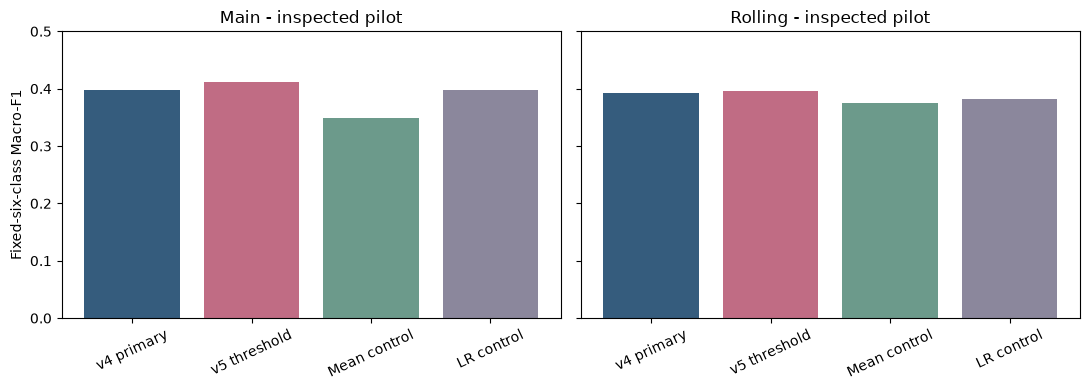

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
models = ['HeTCo_v4', 'HeTCo_v5', 'A7v4_mean_pool', 'LR_hier_community']
labels = ['v4 primary', 'v5 threshold', 'Mean control', 'LR control']
for ax, window in zip(axes, ['main', 'rolling']):
    selected = {r['model']: r for r in scores if r['window'] == window}
    ax.bar(labels, [float(selected[m]['macro_f1']) for m in models], color=['#355C7D', '#C06C84', '#6C9A8B', '#8B879C'])
    ax.set_title(window.capitalize() + ' - inspected pilot')
    ax.tick_params(axis='x', rotation=25)
    ax.set_ylim(0, .5)
axes[0].set_ylabel('Fixed-six-class Macro-F1')
fig.tight_layout()
figures = root / 'reports/figures/h1-ablation-20261109'
figures.mkdir(parents=True, exist_ok=True)
fig.savefig(figures / 'comparison.png', dpi=160, bbox_inches='tight')
plt.show()

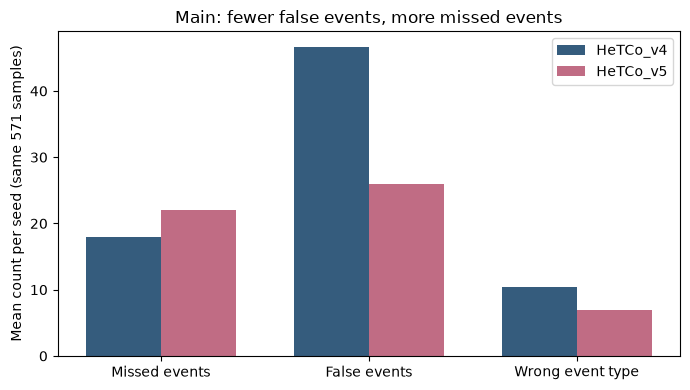

In [4]:
main = {r['model']: r for r in scores if r['window'] == 'main'}
fig, ax = plt.subplots(figsize=(7, 4))
labels = ['Missed events', 'False events', 'Wrong event type']
fields = ['missed_events', 'false_events', 'wrong_event_type']
for offset, model, color in [(-.18, 'HeTCo_v4', '#355C7D'), (.18, 'HeTCo_v5', '#C06C84')]:
    ax.bar([i+offset for i in range(3)], [float(main[model][k]) for k in fields], width=.36, label=model, color=color)
ax.set_xticks(range(3), labels)
ax.set_ylabel('Mean count per seed (same 571 samples)')
ax.set_title('Main: fewer false events, more missed events')
ax.legend()
fig.tight_layout()
fig.savefig(figures / 'tier1-errors.png', dpi=160, bbox_inches='tight')
plt.show()
assert float(main['HeTCo_v5']['missed_events']) > float(main['HeTCo_v4']['missed_events'])

In [5]:
intervals = json.loads((tables / 'saved-intervals.json').read_text())
for r in intervals:
    if r['model'] == 'HeTCo_v5' and r['reference'] == 'HeTCo_v4':
        print(r['scope'], {k: r[k] for k in ('low', 'high')})
        assert r['low'] <= 0 <= r['high']
print('Per-class records:', len(rows('per-class.csv')))

main_community {'low': -0.004311776274626001, 'high': 0.027941852659803815}
rolling_month_blocks {'low': -0.01406400190223489, 'high': 0.013148603886626309}
Per-class records: 72


## Interpretation and delivery boundary

H1 is not supported in its predicted direction. The selected attention threshold is 0.3; mean pooling and community-only hierarchical LR retain argmax. The small Macro-F1 increase accompanies more missed events, while both paired intervals include zero. Keep v4 primary and report v5 as ablation.

Main and rolling windows overlap; rolling July-September was used for selection. Seeds are repeated runs on the same cases. No unseen-data, causal, annotation-completion or universal-superiority claim follows. The full real-data replay, fit log, source snapshot and private keyed predictions are referenced by `reports/H1_ABLATION_REPORT.md`.